# Bart Projesi

# San Francisco Metrosu BART Projesi

Bu proje, **2016-2017 yıllarına ait yolcu ve istasyon verilerini** kullanarak, BART metrosu hakkında önemli sorulara cevap bulmayı amaçlıyor.

## Amaçlanan Sorular

### Veri Analitiği Soruları
- **Hangi BART istasyonu en yoğun?**
- **En az popüler BART güzergahı hangisidir?**
- **Berkeley'den San Francisco'ya gitmek için en iyi zaman ne zaman?**
- **Haftanın hangi günü en yoğun?**
- **Gece geç saatlerde BART'a kaç kişi biniyor?**

### Veri Bilimi Soruları
- **Soru A:** Her istasyon arasındaki düz hat mesafesini hesaplayın.
- **Soru B:** Herhangi 2 istasyon arasında BART ile işe gidip gelen kişi sayısını tahmin edebilen bir model oluşturun:
  - Bu soruya nasıl yaklaşırdınız?
  - Hangi ek verilere ihtiyacınız olurdu?
  - Şehir veya BART yetkililerinin bu verileri nasıl kullanmasını istersiniz?

## Veri Hazırlığı
- **2016 ve 2017 yolcu verilerini birleştirin.**
- **İstasyon verilerini bu veriyle birleştirerek sorulara yanıt bulun.**


# Exploratory Data Analysis (EDA)

In [7]:
import pandas as pd
pd.set_option("display.max_columns",100)
pd.set_option("display.width",100)

In [8]:
df1=pd.read_csv('date-hour-soo-dest-2016.csv')

In [9]:
df2=pd.read_csv('date-hour-soo-dest-2017.csv')

In [10]:
df=pd.concat([df1,df2])

In [11]:
df.head()

,Date,Hour,Origin Station,Destination Station,Trip Count,NC,7
0,2016-01-01,0.0,12TH,12TH,1.0,NaN,NaN
1,2016-01-01,0.0,12TH,16TH,1.0,NaN,NaN
2,2016-01-01,0.0,12TH,24TH,4.0,NaN,NaN
3,2016-01-01,0.0,12TH,ASHB,4.0,NaN,NaN
4,2016-01-01,0.0,12TH,BALB,2.0,NaN,NaN


In [12]:
df['Hour'].value_counts()

,count
Hour,
17.0,139403
18.0,138911
16.0,135000
9.0,129035
19.0,128591
15.0,127275
8.0,126888
14.0,122534
10.0,121115


In [13]:
df.info()


<class 'pandas.core.frame.DataFrame'>
Index: 2418663 entries, 0 to ('2017-03-22', 8, 'BAYF')
Data columns (total 7 columns):
 #   Column               Dtype  
---  ------               -----  
 0   Date                 object 
 1   Hour                 float64
 2   Origin Station       object 
 3   Destination Station  object 
 4   Trip Count           float64
 5   NC                   object 
 6   7                    float64
dtypes: float64(3), object(4)
memory usage: 147.6+ MB


In [14]:
df.isnull().sum()

,0
Date,120978
Hour,120979
Origin Station,120979
Destination Station,120979
Trip Count,120979
NC,2297685
7,2297686


In [15]:
df['Origin Station'].value_counts()

,count
Origin Station,
POWL,73220
CIVC,71784
EMBR,71356
MONT,70998
16TH,65771
12TH,64628
DBRK,64000
24TH,63975
19TH,63569


In [16]:
df.shape

(2418663, 7)

### En yoğun istasyon

In [17]:
istasyonlar = df[['Origin Station', 'Destination Station', 'Trip Count']]
en_yoğun_istasyon = istasyonlar.groupby(['Origin Station', 'Destination Station'], as_index=False).sum().loc[lambda x: x['Trip Count'].idxmax()]

In [18]:
en_yoğun_istasyon.head()

,1490
Origin Station,POWL
Destination Station,BALB
Trip Count,212219.0


### En az popüler BART güzergahı

In [19]:
sirali_istasyonlar = istasyonlar.sort_values(by='Trip Count', ascending=True)
en_az_populer_guzergah = sirali_istasyonlar.iloc[0]
print("En az popüler BART güzergahı:")
print(en_az_populer_guzergah)

En az popüler BART güzergahı:
Origin Station         12TH
Destination Station    12TH
Trip Count              1.0
Name: 0, dtype: object


### Berkeley'den SF'ye gitmek için en iyi zaman

In [20]:
 # Origin Station ve Destination Station sutunlarını bir araya toplayarak yeni bir sütun oluşturuyorum.
df["Route"] = df["Origin Station"]+"-"+df["Destination Station"]

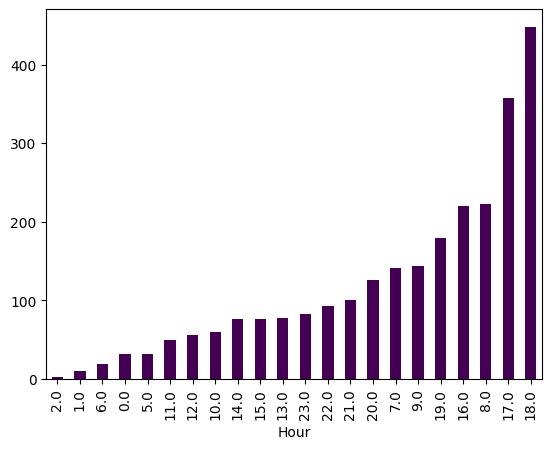

In [21]:
df[df.Route == "DBRK-SSAN"].groupby("Hour")["Trip Count"].sum().sort_values().plot.bar(colormap="viridis");

In [68]:
# En uygun zaman saat 2

### Haftanın en yoğun günü

In [23]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 2418663 entries, 0 to ('2017-03-22', 8, 'BAYF')
Data columns (total 8 columns):
 #   Column               Dtype  
---  ------               -----  
 0   Date                 object 
 1   Hour                 float64
 2   Origin Station       object 
 3   Destination Station  object 
 4   Trip Count           float64
 5   NC                   object 
 6   7                    float64
 7   Route                object 
dtypes: float64(3), object(5)
memory usage: 230.6+ MB


In [24]:
# Date sütununu tarih formatına çevirip gün ay ve yılı ayrı bir sütuna atıyoruz.
df['Date'] = pd.to_datetime(df['Date'])

df["Year"] = df["Date"].dt.year
df["Month"] = df["Date"].dt.month
df["Day"] = df["Date"].dt.day
df["MonthName"] = df["Date"].dt.month_name()
df["DayName"] = df["Date"].dt.day_name()

In [25]:
df.head()

,Date,Hour,Origin Station,Destination Station,Trip Count,NC,7,Route,Year,Month,Day,MonthName,DayName
0,2016-01-01,0.0,12TH,12TH,1.0,NaN,NaN,12TH-12TH,2016.0,1.0,1.0,January,Friday
1,2016-01-01,0.0,12TH,16TH,1.0,NaN,NaN,12TH-16TH,2016.0,1.0,1.0,January,Friday
2,2016-01-01,0.0,12TH,24TH,4.0,NaN,NaN,12TH-24TH,2016.0,1.0,1.0,January,Friday
3,2016-01-01,0.0,12TH,ASHB,4.0,NaN,NaN,12TH-ASHB,2016.0,1.0,1.0,January,Friday
4,2016-01-01,0.0,12TH,BALB,2.0,NaN,NaN,12TH-BALB,2016.0,1.0,1.0,January,Friday


In [26]:
import matplotlib as plt
import seaborn as sns

In [27]:
# suzun kaggle dan alındı
gunluk_yolcu = df.groupby('DayName')['Trip Count'].sum()
en_yogun_gun = gunluk_yolcu.idxmax()
en_yogun_gun

'Thursday'

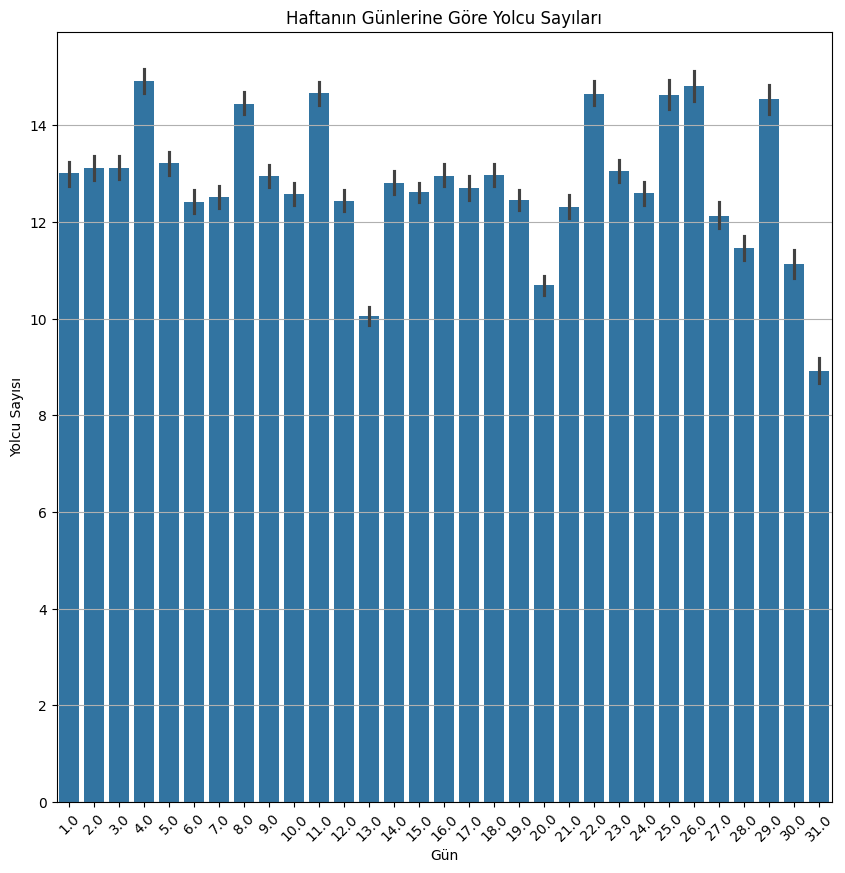

In [28]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(10, 10))
sns.barplot(data=df, x='Day', y='Trip Count')
plt.title('Haftanın Günlerine Göre Yolcu Sayıları')
plt.xlabel('Gün')
plt.ylabel('Yolcu Sayısı')
plt.xticks(rotation=45)
plt.grid(axis='y')
plt.show()

### Gece Geç saatlerde yolcu sayısı

In [29]:
gece_saatleri = df[(df['Hour'] >= 22) | (df['Hour'] < 6)]
toplam_yolcu_sayisi = gece_saatleri['Trip Count'].sum()
toplam_yolcu_sayisi

1985000.0

#### Her istasyon arası mesafe

In [30]:
# Alttaki 2 soru için uğraştım ama yapamadım. Kodlar Adem Bakırcı dan alındı
# https://www.kaggle.com/code/adembakrc/bart-project

In [31]:
df_dis=pd.read_csv('station_info.csv')

In [32]:
df = pd.merge(df,df_dis, left_on="Origin Station", right_on="Abbreviation")
df.head()

,Date,Hour,Origin Station,Destination Station,Trip Count,NC,7,Route,Year,Month,Day,MonthName,DayName,Abbreviation,Description,Location,Name
0,2016-01-01,0.0,12TH,12TH,1.0,NaN,NaN,12TH-12TH,2016.0,1.0,1.0,January,Friday,12TH,"1245 Broadway, Oakland CA 94612<br />12th St. ...","-122.271450,37.803768,0",12th St. Oakland City Center (12TH)
1,2016-01-01,0.0,12TH,16TH,1.0,NaN,NaN,12TH-16TH,2016.0,1.0,1.0,January,Friday,12TH,"1245 Broadway, Oakland CA 94612<br />12th St. ...","-122.271450,37.803768,0",12th St. Oakland City Center (12TH)
2,2016-01-01,0.0,12TH,24TH,4.0,NaN,NaN,12TH-24TH,2016.0,1.0,1.0,January,Friday,12TH,"1245 Broadway, Oakland CA 94612<br />12th St. ...","-122.271450,37.803768,0",12th St. Oakland City Center (12TH)
3,2016-01-01,0.0,12TH,ASHB,4.0,NaN,NaN,12TH-ASHB,2016.0,1.0,1.0,January,Friday,12TH,"1245 Broadway, Oakland CA 94612<br />12th St. ...","-122.271450,37.803768,0",12th St. Oakland City Center (12TH)
4,2016-01-01,0.0,12TH,BALB,2.0,NaN,NaN,12TH-BALB,2016.0,1.0,1.0,January,Friday,12TH,"1245 Broadway, Oakland CA 94612<br />12th St. ...","-122.271450,37.803768,0",12th St. Oakland City Center (12TH)


In [33]:
df["longitude"] = df["Location"].apply(lambda x: float(x.split(",")[0]))
df["latitute"] = df["Location"].apply(lambda x: float(x.split(",")[1]))

In [34]:
df

,Date,Hour,Origin Station,Destination Station,Trip Count,NC,7,Route,Year,Month,Day,MonthName,DayName,Abbreviation,Description,Location,Name,longitude,latitute
0,2016-01-01,0.0,12TH,12TH,1.0,NaN,NaN,12TH-12TH,2016.0,1.0,1.0,January,Friday,12TH,"1245 Broadway, Oakland CA 94612<br />12th St. ...","-122.271450,37.803768,0",12th St. Oakland City Center (12TH),-122.27145,37.803768
1,2016-01-01,0.0,12TH,16TH,1.0,NaN,NaN,12TH-16TH,2016.0,1.0,1.0,January,Friday,12TH,"1245 Broadway, Oakland CA 94612<br />12th St. ...","-122.271450,37.803768,0",12th St. Oakland City Center (12TH),-122.27145,37.803768
2,2016-01-01,0.0,12TH,24TH,4.0,NaN,NaN,12TH-24TH,2016.0,1.0,1.0,January,Friday,12TH,"1245 Broadway, Oakland CA 94612<br />12th St. ...","-122.271450,37.803768,0",12th St. Oakland City Center (12TH),-122.27145,37.803768
3,2016-01-01,0.0,12TH,ASHB,4.0,NaN,NaN,12TH-ASHB,2016.0,1.0,1.0,January,Friday,12TH,"1245 Broadway, Oakland CA 94612<br />12th St. ...","-122.271450,37.803768,0",12th St. Oakland City Center (12TH),-122.27145,37.803768
4,2016-01-01,0.0,12TH,BALB,2.0,NaN,NaN,12TH-BALB,2016.0,1.0,1.0,January,Friday,12TH,"1245 Broadway, Oakland CA 94612<br />12th St. ...","-122.271450,37.803768,0",12th St. Oakland City Center (12TH),-122.27145,37.803768
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2297679,2016-03-25,7.0,MCAR,COLM,2.0,NaN,NaN,MCAR-COLM,2016.0,3.0,25.0,March,Friday,MCAR,"555 40th Street, Oakland CA 94609<br />MacArth...","-122.267040,37.829065,0",MacArthur (MCAR),-122.26704,37.829065
2297680,2016-03-25,7.0,MCAR,COLS,9.0,NaN,NaN,MCAR-COLS,2016.0,3.0,25.0,March,Friday,MCAR,"555 40th Street, Oakland CA 94609<br />MacArth...","-122.267040,37.829065,0",MacArthur (MCAR),-122.26704,37.829065
2297681,2016-03-25,7.0,MCAR,CONC,4.0,NaN,NaN,MCAR-CONC,2016.0,3.0,25.0,March,Friday,MCAR,"555 40th Street, Oakland CA 94609<br />MacArth...","-122.267040,37.829065,0",MacArthur (MCAR),-122.26704,37.829065
2297682,2016-03-25,7.0,MCAR,DALY,3.0,NaN,NaN,MCAR-DALY,2016.0,3.0,25.0,March,Friday,MCAR,"555 40th Street, Oakland CA 94609<br />MacArth...","-122.267040,37.829065,0",MacArthur (MCAR),-122.26704,37.829065


In [35]:
df.drop("Location", axis=1, inplace=True)

In [36]:
df_dis = df

In [37]:
from sklearn.metrics.pairwise import haversine_distances
import pandas as pd
import numpy as np

# Convert latitude and longitude to radians for haversine distance calculation
df_dis['lat_radians'] = np.radians(df_dis['latitute'])
df_dis['long_radians'] = np.radians(df_dis['longitude'])

# Since there are 45 unique abbreviations, ensure we're working with unique station locations
# This step assumes each abbreviation has a unique latitude and longitude
# If not, you might need to aggregate or otherwise ensure uniqueness
unique_stations = df_dis.drop_duplicates(subset=['Abbreviation'])

# Extract the radian-converted coordinates into a numpy array for the unique stations
coordinates = unique_stations[['lat_radians', 'long_radians']].to_numpy()

# Calculate the pairwise haversine distances between all unique stations
dist_matrix_radians = haversine_distances(coordinates, coordinates)

# Convert distances from radians to kilometers
dist_matrix_km = dist_matrix_radians * 6371

# Create a DataFrame for the distance matrix, using unique abbreviations for index and columns
df_dist_matrix = pd.DataFrame(
    dist_matrix_km,
    index=unique_stations['Abbreviation'],
    columns=unique_stations['Abbreviation']
)

In [38]:
df_dist_matrix

Abbreviation,12TH,16TH,19TH,24TH,ASHB,BALB,BAYF,CAST,CIVC,COLM,COLS,CONC,DALY,DBRK,DELN,DUBL,EMBR,FRMT,FTVL,GLEN,HAYW,LAFY,LAKE,MCAR,MLBR,MONT,NBRK,NCON,OAKL,ORIN,PHIL,PITT,PLZA,POWL,RICH,ROCK,SANL,SBRN,SFIA,SHAY,SSAN,UCTY,WCRK,WDUB,WOAK
Abbreviation,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
12TH,0.000000,13.720175,0.567617,14.097927,5.453806,17.972899,17.421986,21.318066,12.818548,21.651800,8.602724,28.452150,20.488348,7.381976,14.064957,34.641522,11.099285,37.726994,5.254274,16.294042,22.027147,16.279546,0.930228,2.839447,24.795767,11.500185,7.876464,30.993614,11.334582,11.315857,23.450324,37.305931,11.254330,12.186511,16.442537,4.881371,13.315746,22.428251,23.437267,26.644817,21.698728,32.578345,21.179219,32.315075,2.084928
16TH,13.720175,0.000000,14.123076,1.406790,16.370223,5.417745,26.873362,31.369785,1.703137,9.834954,19.629420,41.399854,7.862292,17.710613,19.956444,46.313509,3.678977,45.322092,17.219854,3.768466,31.123107,29.571877,14.036737,15.184031,18.552504,3.163421,17.025981,43.624344,19.134809,24.249960,36.740696,50.306911,18.615264,2.391407,19.977128,17.236833,23.259691,14.158399,16.751655,35.047867,11.411739,40.370112,34.647001,43.824988,11.806930
19TH,0.567617,14.123076,0.000000,14.537177,4.944611,18.449743,17.594397,21.423040,13.176704,22.162579,8.759155,27.927226,20.972364,6.866855,13.652407,34.575547,11.413346,37.927682,5.396993,16.761912,22.193837,15.772063,1.294459,2.307486,25.363052,11.827735,7.411705,30.454558,11.680862,10.773359,22.948482,36.787537,10.815966,12.530541,16.099056,4.316179,13.491787,22.989786,24.004818,26.832791,22.238484,32.780913,20.697326,32.267711,2.363310
24TH,14.097927,1.406790,14.537177,0.000000,17.138578,4.296647,26.382151,30.899845,3.051922,8.647687,19.454198,42.092373,6.828586,18.567582,21.157028,45.989716,4.861216,44.508828,17.231066,2.560421,30.546688,30.156601,14.327988,15.774585,17.148474,4.372678,17.959316,44.384429,18.629589,24.894688,37.339178,50.997728,19.709716,3.668896,21.283104,17.885535,22.878946,12.756104,15.346553,34.367219,10.069632,39.597423,35.183337,43.483323,12.280671
ASHB,5.453806,16.370223,4.944611,17.138578,0.000000,21.355016,21.438504,24.836544,15.038489,25.435815,12.762538,25.053770,23.915627,1.931222,9.023275,36.672412,12.990622,41.772579,9.560819,19.604034,25.948929,13.531585,6.216814,2.652851,29.895394,13.494601,2.630089,27.257098,16.331015,8.088818,20.581818,33.957113,6.091619,14.299741,11.850630,1.872092,17.430801,27.148960,28.448090,30.663606,25.948183,36.657191,18.717531,34.527755,5.766857
BALB,17.972899,5.417745,18.449743,4.296647,21.355016,0.000000,28.370186,32.896601,7.100637,4.426359,22.326582,46.215044,2.560946,22.828351,25.374187,48.284910,9.084916,45.301700,20.509238,1.754601,32.237574,34.185441,18.090735,19.859788,14.512558,8.575488,22.246533,48.564235,20.718954,28.995894,41.370956,55.112936,23.993534,7.808705,25.332068,22.011712,25.213150,9.717283,12.706137,35.692841,6.383547,40.567612,39.147064,45.742854,16.283721
BAYF,17.421986,26.873362,17.594397,26.382151,21.438504,28.370186,0.000000,4.531980,26.914792,29.923394,8.836838,31.947031,30.155769,22.928463,30.382150,20.008136,26.068034,20.365540,12.198752,27.328128,4.607425,21.822855,16.508945,19.196143,25.303058,26.239989,24.035914,35.210338,7.752571,20.793251,26.480943,39.184309,27.433911,26.594946,33.285280,19.759903,4.106354,26.340207,25.078559,9.252500,28.171545,15.232015,23.766972,17.447384,19.075498
CAST,21.318066,31.369785,21.423040,30.899845,24.836544,32.896601,4.531980,0.000000,31.370282,34.380122,12.755491,31.731127,34.661193,26.154416,33.585225,15.570095,30.458562,17.194416,16.066778,31.860095,2.544392,22.917755,20.433426,22.798554,29.179789,30.649412,27.362164,35.029355,12.274283,22.926198,26.489444,38.245665,30.660487,31.029730,36.648450,23.060080,8.262625,30.561191,29.103355,6.474328,32.551621,12.255757,23.892538,13.004394,23.100389
CIVC,12.818548,1.703137,13.176704,3.051922,15.038489,7.100637,26.914792,31.370282,0.000000,11.524301,19.315585,40.092237,9.505217,16.291033,18.

In [39]:
df_dis.head()

,Date,Hour,Origin Station,Destination Station,Trip Count,NC,7,Route,Year,Month,Day,MonthName,DayName,Abbreviation,Description,Name,longitude,latitute,lat_radians,long_radians
0,2016-01-01,0.0,12TH,12TH,1.0,NaN,NaN,12TH-12TH,2016.0,1.0,1.0,January,Friday,12TH,"1245 Broadway, Oakland CA 94612<br />12th St. ...",12th St. Oakland City Center (12TH),-122.27145,37.803768,0.6598,-2.134039
1,2016-01-01,0.0,12TH,16TH,1.0,NaN,NaN,12TH-16TH,2016.0,1.0,1.0,January,Friday,12TH,"1245 Broadway, Oakland CA 94612<br />12th St. ...",12th St. Oakland City Center (12TH),-122.27145,37.803768,0.6598,-2.134039
2,2016-01-01,0.0,12TH,24TH,4.0,NaN,NaN,12TH-24TH,2016.0,1.0,1.0,January,Friday,12TH,"1245 Broadway, Oakland CA 94612<br />12th St. ...",12th St. Oakland City Center (12TH),-122.27145,37.803768,0.6598,-2.134039
3,2016-01-01,0.0,12TH,ASHB,4.0,NaN,NaN,12TH-ASHB,2016.0,1.0,1.0,January,Friday,12TH,"1245 Broadway, Oakland CA 94612<br />12th St. ...",12th St. Oakland City Center (12TH),-122.27145,37.803768,0.6598,-2.134039
4,2016-01-01,0.0,12TH,BALB,2.0,NaN,NaN,12TH-BALB,2016.0,1.0,1.0,January,Friday,12TH,"1245 Broadway, Oakland CA 94612<br />12th St. ...",12th St. Oakland City Center (12TH),-122.27145,37.803768,0.6598,-2.134039


In [40]:
df_dis.head()

,Date,Hour,Origin Station,Destination Station,Trip Count,NC,7,Route,Year,Month,Day,MonthName,DayName,Abbreviation,Description,Name,longitude,latitute,lat_radians,long_radians
0,2016-01-01,0.0,12TH,12TH,1.0,NaN,NaN,12TH-12TH,2016.0,1.0,1.0,January,Friday,12TH,"1245 Broadway, Oakland CA 94612<br />12th St. ...",12th St. Oakland City Center (12TH),-122.27145,37.803768,0.6598,-2.134039
1,2016-01-01,0.0,12TH,16TH,1.0,NaN,NaN,12TH-16TH,2016.0,1.0,1.0,January,Friday,12TH,"1245 Broadway, Oakland CA 94612<br />12th St. ...",12th St. Oakland City Center (12TH),-122.27145,37.803768,0.6598,-2.134039
2,2016-01-01,0.0,12TH,24TH,4.0,NaN,NaN,12TH-24TH,2016.0,1.0,1.0,January,Friday,12TH,"1245 Broadway, Oakland CA 94612<br />12th St. ...",12th St. Oakland City Center (12TH),-122.27145,37.803768,0.6598,-2.134039
3,2016-01-01,0.0,12TH,ASHB,4.0,NaN,NaN,12TH-ASHB,2016.0,1.0,1.0,January,Friday,12TH,"1245 Broadway, Oakland CA 94612<br />12th St. ...",12th St. Oakland City Center (12TH),-122.27145,37.803768,0.6598,-2.134039
4,2016-01-01,0.0,12TH,BALB,2.0,NaN,NaN,12TH-BALB,2016.0,1.0,1.0,January,Friday,12TH,"1245 Broadway, Oakland CA 94612<br />12th St. ...",12th St. Oakland City Center (12TH),-122.27145,37.803768,0.6598,-2.134039


In [41]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [42]:
df.shape

(2297684, 20)

In [43]:
df.head()

,Date,Hour,Origin Station,Destination Station,Trip Count,NC,7,Route,Year,Month,Day,MonthName,DayName,Abbreviation,Description,Name,longitude,latitute,lat_radians,long_radians
0,2016-01-01,0.0,12TH,12TH,1.0,NaN,NaN,12TH-12TH,2016.0,1.0,1.0,January,Friday,12TH,"1245 Broadway, Oakland CA 94612<br />12th St. ...",12th St. Oakland City Center (12TH),-122.27145,37.803768,0.6598,-2.134039
1,2016-01-01,0.0,12TH,16TH,1.0,NaN,NaN,12TH-16TH,2016.0,1.0,1.0,January,Friday,12TH,"1245 Broadway, Oakland CA 94612<br />12th St. ...",12th St. Oakland City Center (12TH),-122.27145,37.803768,0.6598,-2.134039
2,2016-01-01,0.0,12TH,24TH,4.0,NaN,NaN,12TH-24TH,2016.0,1.0,1.0,January,Friday,12TH,"1245 Broadway, Oakland CA 94612<br />12th St. ...",12th St. Oakland City Center (12TH),-122.27145,37.803768,0.6598,-2.134039
3,2016-01-01,0.0,12TH,ASHB,4.0,NaN,NaN,12TH-ASHB,2016.0,1.0,1.0,January,Friday,12TH,"1245 Broadway, Oakland CA 94612<br />12th St. ...",12th St. Oakland City Center (12TH),-122.27145,37.803768,0.6598,-2.134039
4,2016-01-01,0.0,12TH,BALB,2.0,NaN,NaN,12TH-BALB,2016.0,1.0,1.0,January,Friday,12TH,"1245 Broadway, Oakland CA 94612<br />12th St. ...",12th St. Oakland City Center (12TH),-122.27145,37.803768,0.6598,-2.134039


# Herhangi 2 istasyon arasında Bart ile işe gidip gelen kişi sayısını tahmin edebilen bir model

In [44]:
dff = df[(df["DayName"]!="Sunday") & (df["DayName"]!="Saturday")]
# filtering all days exclude saturday and sunday for commuting to work

In [45]:
dff['Hour'].value_counts()

,count
Hour,
17.0,105069
18.0,104715
8.0,101100
16.0,100819
7.0,99237
9.0,96914
19.0,96453
15.0,93407
14.0,88765


In [46]:
dff = dff[(dff.Hour>=16) & (dff.Hour<=19)] # İşden çıkış saatlerinin ortalama bir aralığını aldık.

In [47]:
dff.groupby(["Route", "Hour"])["Trip Count"].sum()

Route      Hour
12TH-12TH  16.0     225.0
           17.0     321.0
           18.0     226.0
           19.0     121.0
12TH-16TH  16.0    1317.0
                    ...  
WOAK-WDUB  19.0      33.0
WOAK-WOAK  16.0     113.0
           17.0     173.0
           18.0     117.0
           19.0      75.0
Name: Trip Count, Length: 8094, dtype: float64

In [48]:
dff["work_hour"] = dff.groupby(["Route", "Hour"])["Trip Count"].transform("sum")

<ipython-input-48-9aa0ff2539ad>:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dff["work_hour"] = dff.groupby(["Route", "Hour"])["Trip Count"].transform("sum")


In [49]:
dff.groupby("Route")["Trip Count"].sum()

,Trip Count
Route,
12TH-12TH,893.0
12TH-16TH,8584.0
12TH-19TH,1097.0
12TH-24TH,9856.0
12TH-ASHB,8960.0
...,...
WOAK-SSAN,185.0
WOAK-UCTY,220.0
WOAK-WCRK,219.0


In [50]:
dff["work_route"] = dff.groupby("Route")["Trip Count"].transform("sum")

In [51]:
dff1 = dff[["Trip Count","Year","Month","Day","Hour","longitude","latitute","work_hour","work_route"]]

In [52]:
dff.to_pickle("dff1.pkl")

In [53]:
dff1.reset_index(drop="index",inplace=True)

In [54]:
x = dff1.drop("work_route", axis=1)
y = dff1[["work_route"]]

In [55]:
y.isnull().sum()

,0
work_route,0


In [56]:
from sklearn.model_selection import train_test_split

In [57]:
x_train,x_test,y_train,y_test=train_test_split(x,y, test_size=.20,random_state=42)

In [58]:
#!pip install tensorflow

In [59]:
from tensorflow import keras
from keras.models import Sequential
from keras.layers import Dense

In [60]:
model = Sequential()

model.add(Dense(64, activation="relu"))
model.add(Dense(32, activation="relu"))
model.add(Dense(16, activation="relu"))
model.add(Dense(8, activation="relu"))
model.add(Dense(1))

model.compile(loss="mse", optimizer="adam")

In [61]:
history = model.fit(x_train, y_train, validation_data=(x_test, y_test), batch_size=32, epochs=10)

Epoch 1/10
10177/10177 ━━━━━━━━━━━━━━━━━━━━ 23s 2ms/step - loss: 17524834.0000 - val_loss: 11697004.0000
Epoch 2/10
10177/10177 ━━━━━━━━━━━━━━━━━━━━ 43s 2ms/step - loss: 11758976.0000 - val_loss: 12029615.0000
Epoch 3/10
10177/10177 ━━━━━━━━━━━━━━━━━━━━ 41s 2ms/step - loss: 11727208.0000 - val_loss: 11564822.0000
Epoch 4/10
10177/10177 ━━━━━━━━━━━━━━━━━━━━ 21s 2ms/step - loss: 11652577.0000 - val_loss: 11777490.0000
Epoch 5/10
10177/10177 ━━━━━━━━━━━━━━━━━━━━ 41s 2ms/step - loss: 11655489.0000 - val_loss: 11600144.0000
Epoch 6/10
10177/10177 ━━━━━━━━━━━━━━━━━━━━ 43s 2ms/step - loss: 11995121.0000 - val_loss: 11592218.0000
Epoch 7/10
10177/10177 ━━━━━━━━━━━━━━━━━━━━ 42s 2ms/step - loss: 11770633.0000 - val_loss: 11554880.0000
Epoch 8/10
10177/10177 ━━━━━━━━━━━━━━━━━━━━ 24s 2ms/step - loss: 11702652.0000 - val_loss: 11630764.0000
Epoch 9/10
10177/10177 ━━━━━━━━━━━━━━━━━━━━ 26s 3ms/step - loss: 11576940.0000 - val_loss: 11553532.0000
Epoch 10/10
10177/10177 ━━━━━━━━━━━━━━━━━━━━ 24s 2ms/st

In [62]:
tahmin=model.predict(x_test)

2545/2545 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step


In [63]:
from sklearn.metrics import r2_score, mean_squared_error

In [64]:
r2_score(y_test,tahmin)

0.8900846242904663

In [65]:
mean_squared_error(y_test,tahmin)**.5

3477.8694730105335

In [66]:
loss_f=pd.DataFrame(history.history)

<Axes: >

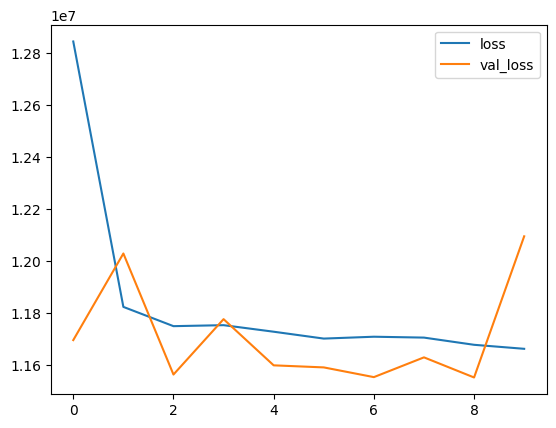

In [67]:
loss_f.plot()